In [ ]:
import random
from pathlib import Path

import numpy as np
import open_clip
import torch
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont
from torchvision import transforms as T

SLIKE = []
DATASET = Path("../dataset/train_ready")
BROJ_SLIKA = 5
SEED = 0

MODEL_ID = "hf-hub:imageomics/bioclip"

In [13]:
EKSTENZIJE = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif", ".tif", ".tiff"}

if SLIKE:
    putanje = [Path(p) for p in SLIKE]
else:
    rng = random.Random(SEED)
    vrste = rng.sample(sorted(p for p in DATASET.iterdir() if p.is_dir()), BROJ_SLIKA)
    putanje = [
        rng.choice(sorted(f for f in v.rglob("*") if f.suffix.lower() in EKSTENZIJE))
        for v in vrste
    ]

oznake = [f"{i} ({p.parent.name})" for i, p in enumerate(putanje, 1)]
for oznaka, p in zip(oznake, putanje):
    print(f"{oznaka}: {p}")

1 (backend): C:\Users\mika\Desktop\RAG\projekat\backend\slika3.jpg


In [14]:
model, _, preprocess_val = open_clip.create_model_and_transforms(MODEL_ID)
model.eval()
print(preprocess_val)

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)


In [15]:
FONT = ImageFont.load_default(size=16)


def prikazi_vise(slike, naslovi, visina=300):
    skalirane = [s.convert("RGB").resize((round(s.width * visina / s.height), visina)) for s in slike]
    razmak, traka = 10, 24
    sirina = sum(s.width for s in skalirane) + razmak * (len(skalirane) - 1)
    platno = Image.new("RGB", (sirina, visina + traka), "white")
    crtac = ImageDraw.Draw(platno)
    x = 0
    for s, naslov in zip(skalirane, naslovi):
        crtac.text((x, 2), naslov, fill="black", font=FONT)
        platno.paste(s, (x, traka))
        x += s.width + razmak
    return platno


def u_pil(t):
    """tensor [3, H, W] u opsegu [0, 1] u PIL sliku"""
    return Image.fromarray((t.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8))

1 (backend): 900×506 px, mod RGB


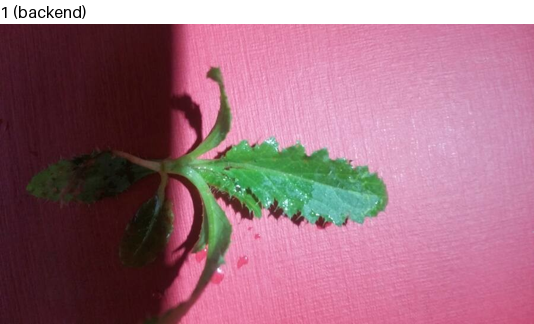

In [ ]:

originali = [Image.open(p) for p in putanje]
for oznaka, o in zip(oznake, originali):
    print(f"{oznaka}: {o.width}×{o.height} px, mod {o.mode}")
display(prikazi_vise(originali, oznake))

1 (backend)
            Resize: 398×224 px, mod RGB
        CenterCrop: 224×224 px, mod RGB
  MaybeConvertMode: 224×224 px, mod RGB


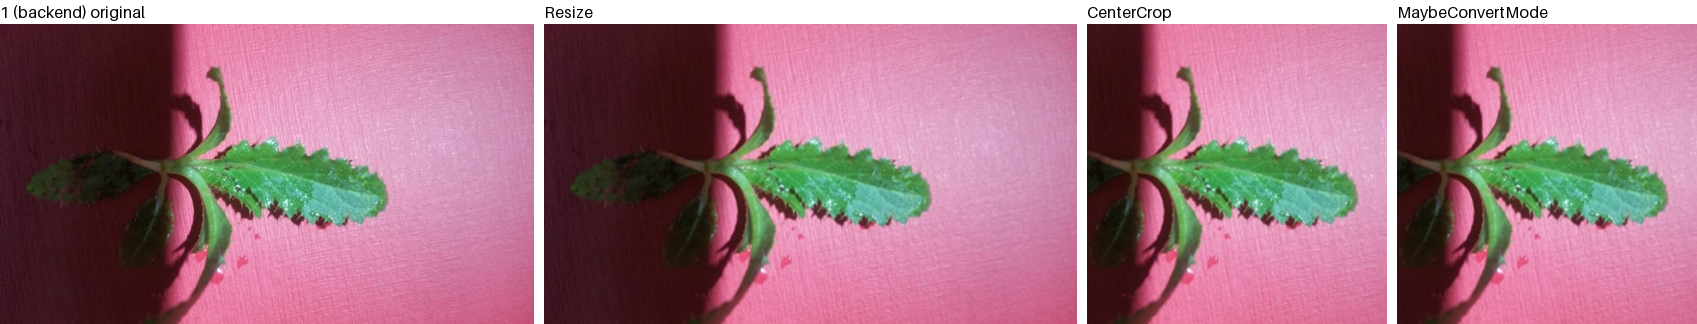

In [17]:
koraci_sve = []
for oznaka, original in zip(oznake, originali):
    koraci, naslovi = [original], [f"{oznaka} original"]
    trenutna = original
    print(oznaka)
    for t in preprocess_val.transforms:
        if isinstance(t, T.ToTensor):
            break
        trenutna = t(trenutna)
        ime = getattr(t, "__name__", type(t).__name__)
        koraci.append(trenutna)
        naslovi.append(ime)
        print(f"{ime:>18}: {trenutna.width}×{trenutna.height} px, mod {trenutna.mode}")
    koraci_sve.append(koraci)
    display(prikazi_vise(koraci, naslovi))

1 (backend): odsečeno 43.8% površine originala


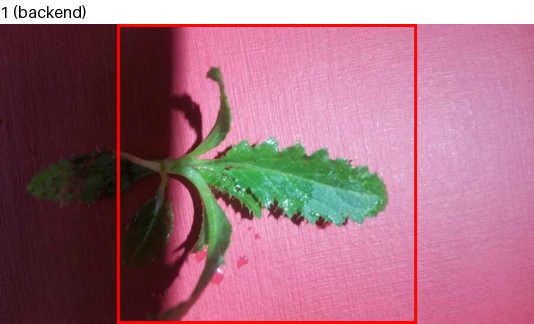

In [18]:
sa_okvirom = []
for oznaka, original in zip(oznake, originali):
    W, H = original.size
    s = min(W, H)
    levo, gore = (W - s) // 2, (H - s) // 2
    slika = original.convert("RGB")
    ImageDraw.Draw(slika).rectangle(
        [levo, gore, levo + s - 1, gore + s - 1], outline="red", width=max(3, s // 100)
    )
    sa_okvirom.append(slika)
    print(f"{oznaka}: odsečeno {100 * (1 - s * s / (W * H)):.1f}% površine originala")
display(prikazi_vise(sa_okvirom, oznake))

In [19]:
x = torch.stack([preprocess_val(o) for o in originali])
print("oblik:", tuple(x.shape), "| tip:", x.dtype)
for oznaka, xi in zip(oznake, x):
    print(oznaka)
    for i, kanal in enumerate("RGB"):
        k = xi[i]
        print(f"  {kanal}: min {k.min().item():.3f}  max {k.max().item():.3f}  sredina {k.mean().item():.3f}")

oblik: (1, 3, 224, 224) | tip: torch.float32
1 (backend)
  R: min -1.675  max 1.930  sredina 0.641
  G: min -1.662  max 2.075  sredina -0.025
  B: min -1.452  max 2.146  sredina 0.366


mean: [0.48145466, 0.4578275, 0.40821073]
std:  [0.26862954, 0.26130258, 0.27577711]
1 (backend): max razlika u odnosu na PIL posle poslednjeg PIL koraka: 0


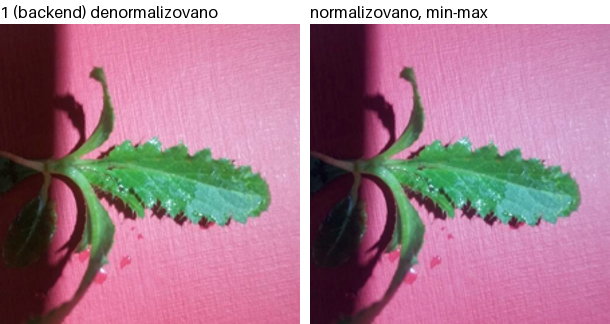

In [20]:
norm = next(t for t in preprocess_val.transforms if isinstance(t, T.Normalize))
mean = torch.tensor(norm.mean).view(3, 1, 1)
std = torch.tensor(norm.std).view(3, 1, 1)
print("mean:", norm.mean)
print("std: ", norm.std)

vracene = []
for oznaka, xi, koraci in zip(oznake, x, koraci_sve):
    vracena = (xi * std + mean).clamp(0, 1)
    sirova = (xi - xi.min()) / (xi.max() - xi.min())
    vracene.append(vracena)

    razlika = np.abs(np.asarray(u_pil(vracena), dtype=int) - np.asarray(koraci[-1].convert("RGB"), dtype=int))
    print(f"{oznaka}: max razlika u odnosu na PIL posle poslednjeg PIL koraka: {razlika.max()}")
    display(prikazi_vise([u_pil(vracena), u_pil(sirova)], [f"{oznaka} denormalizovano", "normalizovano, min-max"]))

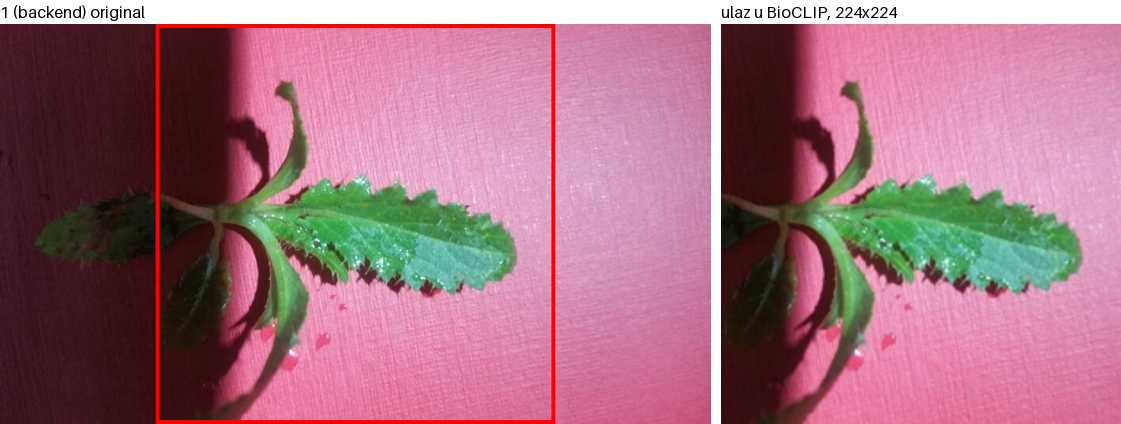

In [21]:
for oznaka, okvir, vracena in zip(oznake, sa_okvirom, vracene):
    display(prikazi_vise(
        [okvir, u_pil(vracena)],
        [f"{oznaka} original", "ulaz u BioCLIP, 224x224"],
        visina=400,
    ))